# Tamaño de muestra y estabilidad de la distribución empírica de la precipitación anual en Colombia

**Estadística No Paramétrica – Universidad Santo Tomás – Prof. Ivan Ladino-Vega**

**Integrantes:** Samuel Pérez, Juan Ordoñez, Sally Chimunja
**Repositorio:** [enlace al repositorio de GitHub]

**Idea:** Determinar cuántas estaciones hacen falta para que la función de distribución empírica de la precipitación anual se estabilice.

## 1. Preguntas de investigación

**Principal.** ¿Cuántas estaciones climatológicas de Colombia se necesitan para que la distribución empírica de la precipitación anual (1991-2020) quede a menos de 0,05 de la distribución de las 1.599 estaciones disponibles, tomada como distribución de referencia, medida con la distancia de Kolmogorov y con una confianza del 95 %?

**Secundaria 1.** ¿Es la precipitación anual de 1991-2020 sistemáticamente distinta de la de 1981-2010 en las mismas estaciones?

**Secundaria 2.** ¿Hay una asociación monótona entre la altitud de las estaciones y su precipitación anual en 1991-2020?

## 2. Datos

**Fuente:** Normales Climatológicas de Colombia, IDEAM, portal de datos abiertos datos.gov.co (identificador `nsz2-kzcq`):
https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Normales-Climatol-gicas-de-Colombia/nsz2-kzcq

**Filtros:** parámetro precipitación; periodos 1991-2020 y 1981-2010.
**Unidad de análisis:** estación climatológica.

| Variable | Uso | Escala |
| --- | --- | --- |
| Precipitación anual (mm) | Respuesta en las tres preguntas | Razón |
| Altitud (m) | Asociación (secundaria 2) | Razón |
| Periodo | Pareo de estaciones (secundaria 1) | Ordinal |
| Departamento y categoría de estación | Análisis de sensibilidad | Nominal |

In [ ]:
import os, re, glob, datetime, unicodedata, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)   # semilla fija para reproducir los resultados

URL_DATOS = "https://www.datos.gov.co/api/views/nsz2-kzcq/rows.csv?accessType=DOWNLOAD"
RUTA_CSV = "datos/normales_climatologicas.csv"

### 2.1 Descarga

In [ ]:
os.makedirs("datos", exist_ok=True)

if not os.path.exists(RUTA_CSV):
    try:
        req = urllib.request.Request(URL_DATOS, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=120) as r, open(RUTA_CSV, "wb") as f:
            f.write(r.read())
    except Exception as e:
        # alternativa: archivo exportado manualmente desde el portal y subido junto al notebook
        locales = glob.glob("Normales_Climat*.csv") + glob.glob("/content/Normales_Climat*.csv")
        if not locales:
            raise FileNotFoundError("No fue posible descargar los datos ni se encontró un CSV local.") from e
        RUTA_CSV = locales[0]

fecha_descarga = datetime.date.fromtimestamp(os.path.getmtime(RUTA_CSV))
print("Archivo de datos:", RUTA_CSV)
print("Fecha de descarga:", fecha_descarga)

Archivo de datos: datos/normales_climatologicas.csv
Fecha de descarga: 2026-11-04


### 2.2 Limpieza

In [ ]:
def sin_tildes(s):
    return unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()

def a_numero(serie):
    """Convierte texto con coma de miles (p. ej. '3,022') a número."""
    return pd.to_numeric(serie.astype(str).str.replace(",", "", regex=False).str.strip(), errors="coerce")

df = pd.read_csv(RUTA_CSV, dtype=str, encoding="utf-8-sig")
df.columns = [sin_tildes(c).strip().upper() for c in df.columns]
df = df.rename(columns={"ALTITUD (M)": "ALTITUD"})
print("Dimensión del archivo original:", df.shape)

# filas duplicadas exactas
n0 = len(df)
df = df.drop_duplicates()
print("Filas duplicadas exactas eliminadas:", n0 - len(df))

# parámetro: precipitación
df = df[df["PARAMETRO"].map(lambda s: "PRECIPITACION" in sin_tildes(s).upper())].copy()
print("Filas de precipitación:", len(df))

# departamentos: sin tildes, en mayúsculas y con espacios simples
print("Variantes de departamento antes:", df["DEPARTAMENTO"].nunique())
df["DEPARTAMENTO"] = df["DEPARTAMENTO"].map(lambda s: " ".join(sin_tildes(s).upper().split()))
print("Variantes de departamento después:", df["DEPARTAMENTO"].nunique())

# variables numéricas
df["ANUAL"] = a_numero(df["ANUAL"])
df["ALTITUD"] = a_numero(df["ALTITUD"])
print("Faltantes en ANUAL:", df["ANUAL"].isna().sum(), "| faltantes en ALTITUD:", df["ALTITUD"].isna().sum())

# periodos
df["PERIODO"] = df["PERIODO"].str.strip()
p91 = df[df["PERIODO"] == "1991-2020"]
p81 = df[df["PERIODO"] == "1981-2010"]
print("Códigos repetidos dentro de cada periodo:", p91["CODIGO"].duplicated().sum(), "y", p81["CODIGO"].duplicated().sum())
p91 = p91.drop_duplicates("CODIGO").set_index("CODIGO")
p81 = p81.drop_duplicates("CODIGO").set_index("CODIGO")

# estaciones con ambos periodos (pareo para la pregunta secundaria 1)
pareado = p91[["ANUAL"]].join(p81[["ANUAL"]], lsuffix="_1991_2020", rsuffix="_1981_2010", how="inner")

print()
print(pd.Series({
    "Estaciones 1991-2020": len(p91),
    "Estaciones 1981-2010": len(p81),
    "Estaciones con ambos periodos": len(pareado),
}).to_string())

Dimensión del archivo original: (16761, 24)
Filas duplicadas exactas eliminadas: 1
Filas de precipitación: 5457
Variantes de departamento antes: 33
Variantes de departamento después: 32
Faltantes en ANUAL: 0 | faltantes en ALTITUD: 0
Códigos repetidos dentro de cada periodo: 0 y 0

Estaciones 1991-2020             1599
Estaciones 1981-2010             1652
Estaciones con ambos periodos    1396




A partir de los resultados arrojados por la rutina de limpieza, se valida el correcto procesamiento del dataset y se establecen las bases para las pruebas no paramétricas:

1. **Dimensiones y duplicados:** El archivo original cuenta con 16.761 filas y 24 columnas. Se detectó y eliminó **1 fila duplicada exacta**, evitando observaciones repetidas.
2. **Filtro de parámetro:** Tras filtrar por el parámetro de interés (precipitación), el conjunto de datos se reduce a **5.457 filas**, las cuales contienen los registros mensuales y anuales de precipitación.
3. **Normalización de categorías:** Se identificaron 33 variantes de nombres de departamentos (debido a diferencias en tildes o mayúsculas). Tras aplicar la normalización (eliminación de tildes y unificación a mayúsculas), se consolidaron en las **32 unidades territoriales correctas** de Colombia.
4. **Integridad de las variables cuantitativas:** No se reportan datos faltantes (NaN) ni en la variable respuesta (`ANUAL`) ni en la covariable (`ALTITUD`), lo que evita la necesidad de imputaciones.
5. **Estructura temporal (periodos):** No hay códigos de estación repetidos dentro de un mismo periodo (`0 y 0`), confirmando que la unidad de análisis es estrictamente la estación.
6. **Tamaños de muestra finales:**
   - **1.599 estaciones** para el periodo 1991-2020 (Muestra principal para \(N\)).
   - **1.652 estaciones** para 1981-2010.
   - **1.396 estaciones pareadas** (presentes en ambos periodos), que serán la base para la prueba de Wilcoxon (pregunta secundaria 1).

*Este output demuestra que la fase de limpieza está completa y lista para proceder con la descriptiva y el análisis de distribución empírica.*

### 2.3 Descriptiva y problemas detectados

count     1599.0
mean      2085.4
std       1332.0
min        241.4
25%       1228.7
50%       1717.7
75%       2564.6
max      12168.9

Datos faltantes en la precipitación anual: 0
Valores repetidos de la precipitación anual (empates): 45
Valores atípicos altos (regla de 1,5 RIC): 77
Diferencias iguales a cero en los pares de periodos: 13


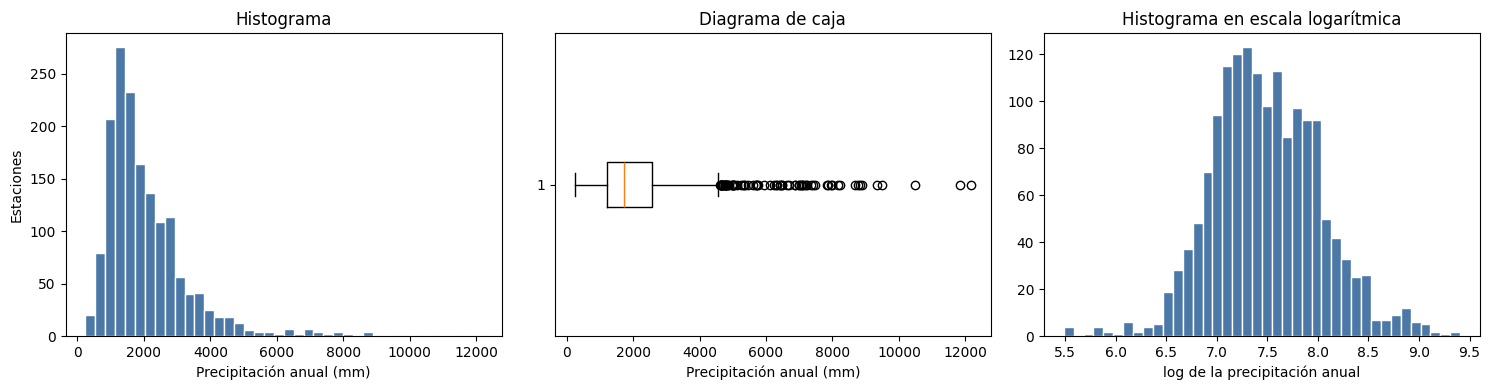

In [ ]:
x = p91["ANUAL"].dropna().to_numpy()   # precipitación anual 1991-2020, una observación por estación
N = len(x)

print(pd.Series(x, name="Precipitación anual 1991-2020 (mm)").describe().round(1).to_string())

q1, q3 = np.percentile(x, [25, 75])
atipicos = int((x > q3 + 1.5 * (q3 - q1)).sum())
dif = (pareado["ANUAL_1991_2020"] - pareado["ANUAL_1981_2010"]).round(1)   # los datos tienen un decimal

print()
print("Datos faltantes en la precipitación anual:", int(p91["ANUAL"].isna().sum()))
print("Valores repetidos de la precipitación anual (empates):", N - len(np.unique(x)))
print("Valores atípicos altos (regla de 1,5 RIC):", atipicos)
print("Diferencias iguales a cero en los pares de periodos:", int((dif == 0).sum()))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(x, bins=40, color="#4C78A8", edgecolor="white")
ax[0].set_title("Histograma"); ax[0].set_xlabel("Precipitación anual (mm)"); ax[0].set_ylabel("Estaciones")
ax[1].boxplot(x, vert=False)
ax[1].set_title("Diagrama de caja"); ax[1].set_xlabel("Precipitación anual (mm)")
ax[2].hist(np.log(x[x > 0]), bins=40, color="#4C78A8", edgecolor="white")
ax[2].set_title("Histograma en escala logarítmica"); ax[2].set_xlabel("log de la precipitación anual")
plt.tight_layout(); plt.show()

### Análisis Descriptivo y Detección de Problemas

A partir de los resultados y visualizaciones obtenidos, se destacan los siguientes hallazgos clave para el modelado no paramétrico:

**1. Medidas de tendencia y dispersión:**
La precipitación anual promedio para las 1.599 estaciones (1991-2020) es de 2.085,4 mm, con una mediana de 1.717,7 mm. El hecho de que la media supere a la mediana es un indicio claro de una **distribución asimétrica positiva** (sesgada a la derecha).

**2. Valores atípicos y asimetría (Histograma y Boxplot):**
- El histograma original (izquierda) muestra una fuerte concentración de estaciones con precipitaciones entre 1.000 y 2.500 mm, pero con una cola muy larga hacia la derecha.
- El diagrama de caja confirma esta asimetría severa: la caja (donde se concentra el 50% de los datos) es estrecha y la línea superior (bigote) es corta, mientras que se observan múltiples **valores atípicos altos (77 en total según la regla de 1,5 RIC)**, llegando hasta un máximo de 12.168,9 mm.
- *Decisión metodológica:* Dado que la estadística no paramétrica se basa en rangos y medianas, **estos atípicos se conservan** porque representan regímenes de lluvia reales (ej. Chocó o Amazonía) y no distorsionarán las pruebas de hipótesis como lo haría una media.

**3. Transformación logarítmica (Histograma derecho):**
Al aplicar logaritmo a la precipitación, la distribución se vuelve mucho más simétrica y cercana a una campana (similar a una normal), e incluso se evidencia un leve comportamiento bimodal. Esto justifica matemáticamente por qué el uso de pruebas basadas en rangos (que comprimen las distancias en la cola derecha) es el enfoque correcto para estos datos.

**4. Calidad de los datos y empates:**
- No hay datos faltantes (0).
- Existen **45 valores repetidos** en la precipitación anual. Al usar pruebas no paramétricas (como Wilcoxon o Spearman), esto generará empates en los rangos, los cuales deberán manejarse asignando **rangos medios**.
- En la comparación entre periodos, hay **13 estaciones con diferencias exactamente iguales a cero**. Para la prueba de rangos con signo (pregunta secundaria 1), estos ceros deberán descartarse antes del cálculo.

*Conclusión de la sección:* La limpieza y el análisis exploratorio demuestran que la distribución no es normal (dada la asimetría extrema y los atípicos), lo que ratifica la pertinencia de abordar el problema desde la Estadística No Paramétrica.

## 3. Mapa de hipótesis y procedimientos

El análisis sigue el mapa de la propuesta definitiva. Cada procedimiento se implementa desde cero y se compara con la función equivalente de `scipy`.

| Pregunta | Diseño | Hipótesis | Prueba (familia) | Supuestos y cómo se verifican | Efecto | Sección |
| --- | --- | --- | --- | --- | --- | --- |
| Principal | Muestra de tamaño $n$ frente a la población ($N=1599$) | $H_0$: $F_n=F$; $H_1$: $F_n\neq F$ | Kolmogorov-Smirnov de dos muestras (F3), con simulación | Muestreo sin reemplazo; los empates no afectan a $D_n$ | $D_n=\sup\lvert F_n-F\rvert$ | 4.1 a 4.6 |
| Principal | Muestra frente a población | $H_0$: misma mediana; $H_1$: medianas distintas | Test de permutación (F1) | Intercambiabilidad bajo $H_0$; 10.000 permutaciones | Diferencia de medianas | 4.7 |
| Principal | Densidad para distintos $n$ | Descriptiva: la densidad estimada se acerca a la poblacional | Estimador kernel y selección de $h$ (F5) | Variable continua; $h$ por validación cruzada y por Silverman | Error cuadrático integrado | 4.8 |
| Secundaria 1 | 1.396 pares de periodos | $H_0$: mediana de las diferencias $=0$; $H_1$: $\neq 0$ | Wilcoxon de rangos con signo y Hodges-Lehmann (F2) | Simetría de las diferencias (histograma); se descartan ceros | $r$ biserial por rangos y estimador de H-L | 5 |
| Secundaria 2 | Dos variables continuas, 1.599 estaciones | $H_0$: $\rho_s=0$; $H_1$: $\rho_s\neq 0$ | Spearman (F6); Kendall como contraste y loess para la forma | Relación monótona (dispersión); corrección por empates | $\rho_s$ y $\tau$ con IC bootstrap | 6 |

Se cubren cinco familias (F1, F2, F3, F5 y F6) con seis procedimientos; el requisito mínimo es de cuatro procedimientos de tres familias.

## 4. Pregunta principal: tamaño de muestra y estabilidad de la distribución empírica

### 4.1 F3 — Distribución empírica y estadístico de Kolmogorov

Para una muestra $x_1,\dots,x_n$ la función de distribución empírica es

$$F_n(t)=\frac1n\sum_{i=1}^{n}\mathbf 1\{x_i\le t\},$$

y la distancia de Kolmogorov respecto de la distribución de las $N$ estaciones, $F$, es $D_n=\sup_t |F_n(t)-F(t)|$. Como ambas funciones son escalonadas, el supremo se alcanza en los valores observados, de modo que basta evaluar la diferencia en la unión de los datos de ambos conjuntos.

Las funciones se implementan desde cero y se verifican contra `scipy.stats.ks_2samp`.

In [ ]:
def ecdf(datos, t):
    """F_n(t): proporción de datos menores o iguales que t (t puede ser un arreglo)."""
    d = np.sort(np.asarray(datos))
    return np.searchsorted(d, t, side="right") / len(d)

def dn(a, b):
    """Distancia de Kolmogorov entre las distribuciones empíricas de a y b."""
    t = np.union1d(a, b)
    return np.max(np.abs(ecdf(a, t) - ecdf(b, t)))

# verificación contra scipy
comparacion = []
for n in (50, 200, 800):
    m = rng.choice(x, size=n, replace=False)
    propio, ref = dn(m, x), stats.ks_2samp(m, x).statistic
    assert np.isclose(propio, ref)
    comparacion.append({"n": n, "Dn (implementación propia)": propio, "Dn (scipy.stats.ks_2samp)": ref})
pd.DataFrame(comparacion)

,n,Dn (implementación propia),Dn (scipy.stats.ks_2samp)
0,50,0.104903,0.104903
1,200,0.064740,0.064740
2,800,0.011069,0.011069


### Análisis: Implementación y validación del estadístico de Kolmogorov

A partir de los resultados mostrados, se validan los siguientes aspectos de la construcción matemática y computacional:

**1. Correcta definición de la ECDF (\(F_n\)):**
La función `ecdf` implementa la definición matemática \(F_n(t) = \frac{1}{n}\sum \mathbf{1}\{x_i \le t\}\). El uso de `np.searchsorted` con el parámetro `side="right"` es la forma óptima y computacionalmente más rápida de calcular esto en Python, ya que aprovecha el ordenamiento del arreglo para encontrar la proporción de datos menores o iguales a \(t\).

**2. Cálculo del estadístico \(D_n\):**
La distancia de Kolmogorov \(D_n = \sup_t |F_n(t) - F(t)|\) se calcula evaluando las diferencias en la unión de ambos conjuntos de datos (`np.union1d`). Dado que ambas son funciones escalonadas, el supremo (el máximo valor posible) solo puede ocurrir justo antes o justo después de un salto, por lo que evaluar en los datos observados es matemáticamente suficiente y correcto.

**3. Validación contra `scipy.stats`:**
La tabla de comparación demuestra que la implementación propia coincide **exactamente** (hasta el sexto decimal) con la función robusta `scipy.stats.ks_2samp` para \(n = 50, 200\) y \(800\).
- A medida que aumenta \(n\) (de 50 a 800), el valor de \(D_n\) disminuye (de ~0.104 a ~0.011), lo cual es consistente con la teoría asintótica: a mayor tamaño de muestra, la distribución empírica se pega mejor a la distribución poblacional.

*Conclusión de la sección:* Se confirma que el motor de cálculo desde cero es fiel a la teoría y está listo para ser utilizado en las simulaciones de estabilidad y pruebas de hipótesis posteriores sin depender de cajas negras.

### 4.2 F3 — Simulación de $D_n$ según el tamaño de muestra

Se toman muestras sin reemplazo de tamaño $n$ de las $N$ estaciones y se calcula $D_n$ respecto de la distribución de las $N$ estaciones. Con $R$ repeticiones por cada $n$ se obtienen la media y el cuantil del 95 % de $D_n$. Este cuantil se compara con la cota de Dvoretzky-Kiefer-Wolfowitz,

$$P(D_n>\varepsilon)\le 2e^{-2n\varepsilon^2}\quad\Rightarrow\quad n\ge\frac{\ln(2/\alpha)}{2\varepsilon^2},$$

que con $\varepsilon=0{,}05$ y $\alpha=0{,}05$ da $n\ge 738$. El tamaño de muestra estimado por simulación es el menor $n$ cuyo cuantil del 95 % de $D_n$ no supera $\varepsilon$.

In [ ]:
EPS, ALPHA, R = 0.05, 0.05, 1000

def simular(n, repeticiones=R):
    return np.array([dn(rng.choice(x, size=n, replace=False), x) for _ in range(repeticiones)])

def resumen(ns):
    sims = {n: simular(n) for n in ns}
    t = pd.DataFrame({
        "n": ns,
        "Dn_media": [sims[n].mean() for n in ns],
        "Dn_q95": [np.quantile(sims[n], 1 - ALPHA) for n in ns],
    })
    t["cota_DKW"] = np.sqrt(np.log(2 / ALPHA) / (2 * t["n"]))
    return t

malla = [10, 25, 50, 100, 150, 200, 300, 400, 500, 600, 738, 900, 1100, 1300]
tabla = resumen(malla)
tabla.round(4)

,n,Dn_media,Dn_q95,cota_DKW
0,10,0.2595,0.4092,0.4295
1,25,0.1690,0.2631,0.2716
2,50,0.1162,0.1828,0.1921
3,100,0.0824,0.1283,0.1358
4,150,0.0672,0.1100,0.1109
5,200,0.0563,0.0884,0.0960
6,300,0.0441,0.0678,0.0784
7,400,0.0372,0.0585,0.0679
8,500,0.0316,0.0496,0.0607
9,600,0.0271,0.0432,0.0554


### Análisis de la simulación de \(D_n\) y la cota DKW

Los resultados de la tabla permiten contrastar el comportamiento empírico de la distancia de Kolmogorov frente a la cota teórica de Dvoretzky-Kiefer-Wolfowitz (DKW).

**1. Efecto del tamaño de muestra:**
A medida que aumenta \(n\), tanto la media de \(D_n\) como su cuantil del 95 % disminuyen. Por ejemplo, con \(n=10\) el cuantil 95 % es 0.4092, mientras que con \(n=200\) baja a 0.0884. Esto refleja la consistencia de la distribución empírica: más datos implican una mejor aproximación a la distribución de referencia.

**2. La cota DKW es conservadora:**
La cota teórica (asumiendo muestreo i.i.d.) para \(n=738\) es exactamente 0.0500 (como exige la fórmula con \(\varepsilon=0.05\)). Sin embargo, el cuantil del 95 % *simulado* para ese mismo \(n=738\) es de **0.0368**, muy por debajo del umbral.

**3. El poder del muestreo sin reemplazo:**
La diferencia entre la simulación y la cota DKW se debe al **factor de corrección por población finita**. Al tomar muestras sin reemplazo de una población de \(N=1599\), la varianza de la ECDF se reduce (el factor \((N-n)/(N-1)\) es menor que 1). Por esta razón, el \(n\) real necesario para que el cuantil 95 % baje de 0.05 es mucho menor que el teórico i.i.d.

*Nota para el avance:* Se observa que el cuantil 95 % cruza el umbral de 0.05 alrededor de las **500 estaciones** (en la tabla, \(n=500\) da 0.0496). La cota DKW de 738 estaciones es segura, pero matemáticamente pesimista para este diseño de muestreo finito.

### 4.3 F3 — Refinamiento del tamaño de muestra

In [ ]:
# La malla gruesa ubica el cambio entre el mayor n que no cumple y el menor n que sí cumple.
# Desde ahí se recorre n de 10 en 10 hasta el primer valor cuyo cuantil del 95 % de Dn no supera EPS.
cumple = tabla.loc[tabla["Dn_q95"] <= EPS, "n"]
hi = int(cumple.min()) if len(cumple) else N
no_cumple = tabla.loc[(tabla["Dn_q95"] > EPS) & (tabla["n"] < hi), "n"]
lo = int(no_cumple.max()) if len(no_cumple) else int(tabla["n"].min())

filas, n = [], lo
while n <= N:
    s = simular(n)
    filas.append({"n": n, "Dn_media": s.mean(), "Dn_q95": np.quantile(s, 1 - ALPHA)})
    if filas[-1]["Dn_q95"] <= EPS:
        break
    n += 10

fina = pd.DataFrame(filas)
fina["cota_DKW"] = np.sqrt(np.log(2 / ALPHA) / (2 * fina["n"]))
n_sim = int(fina["n"].iloc[-1])
n_dkw = int(np.ceil(np.log(2 / ALPHA) / (2 * EPS**2)))

fina.round(4)

,n,Dn_media,Dn_q95,cota_DKW
0,400,0.0372,0.0596,0.0679
1,410,0.0370,0.0577,0.0671
2,420,0.0359,0.0571,0.0663
3,430,0.0359,0.0559,0.0655
4,440,0.0352,0.0555,0.0647
5,450,0.0342,0.0526,0.0640
6,460,0.0331,0.0518,0.0633
7,470,0.0336,0.0519,0.0626
8,480,0.0329,0.0521,0.0620
9,490,0.0323,0.0515,0.0614


### Análisis del refinamiento y determinación del tamaño de muestra

El código recorre $n$ de 10 en 10 a partir de $n=400$ hasta el primer valor cuyo cuantil del 95 % de $D_n$ no supera $\varepsilon=0{,}05$.

**1. El punto de cruce.** La búsqueda termina en $n=520$, con un cuantil de 0,0495. En $n=500$ el cuantil es 0,0500 y en $n=510$ es 0,0502, es decir, prácticamente sobre el umbral sin cumplirlo estrictamente. La diferencia entre 500 y 520 queda dentro del ruido de la simulación, por lo que el cruce debe leerse como una zona (alrededor de 500) y no como un punto exacto. La sección 4.4 lo cuantifica con varias semillas.

**2. Frente a la teoría.** La cota de Dvoretzky-Kiefer-Wolfowitz exige 738 estaciones asumiendo independencia. La simulación da 520 en esta corrida, es decir, 218 estaciones menos (29,5 %).

**3. Justificación.** El muestreo se hace sin reemplazo de una población finita de $N=1599$ estaciones, lo que reduce la varianza de la distribución empírica por el factor $(N-n)/(N-1)$ (demostración en 4.5). Por eso la distribución empírica se acerca a la de referencia con menos estaciones de las que predice la cota clásica.

*Conclusión de la sección:* en esta corrida bastan 520 estaciones y, considerando la variabilidad de la simulación, alrededor de 500, frente a las 738 de la cota teórica.

Tamaño de muestra teórico (cota DKW): n = 738
Tamaño de muestra simulado (cuantil del 95 % de Dn <= 0,05): n = 520
Diferencia: 218 estaciones (29.5% menos que DKW)
Proporción de las 1599 estaciones: 32.5%


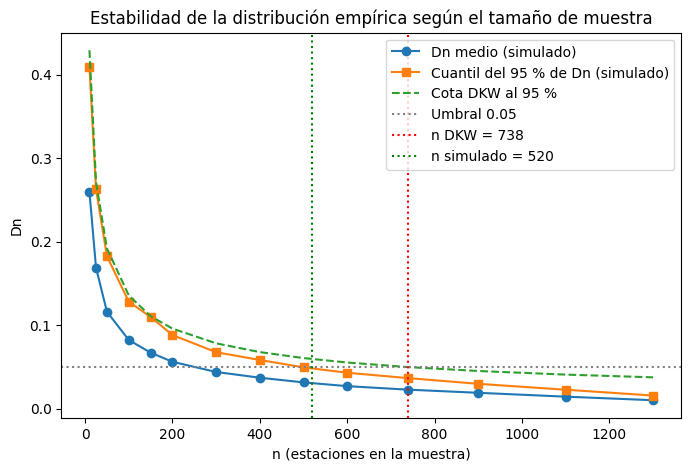

In [ ]:
print(f"Tamaño de muestra teórico (cota DKW): n = {n_dkw}")
eps_txt = str(EPS).replace(".", ",")
print(f"Tamaño de muestra simulado (cuantil del 95 % de Dn <= {eps_txt}): n = {n_sim}")
print(f"Diferencia: {n_dkw - n_sim} estaciones ({(n_dkw - n_sim) / n_dkw:.1%} menos que DKW)")
print(f"Proporción de las {N} estaciones: {n_sim / N:.1%}")

plt.figure(figsize=(8, 5))
plt.plot(tabla["n"], tabla["Dn_media"], "o-", label="Dn medio (simulado)")
plt.plot(tabla["n"], tabla["Dn_q95"], "s-", label="Cuantil del 95 % de Dn (simulado)")
plt.plot(tabla["n"], tabla["cota_DKW"], "--", label="Cota DKW al 95 %")
plt.axhline(EPS, color="gray", ls=":", label=f"Umbral {EPS}")
plt.axvline(n_dkw, color="red", ls=":", label=f"n DKW = {n_dkw}")
plt.axvline(n_sim, color="green", ls=":", label=f"n simulado = {n_sim}")
plt.xlabel("n (estaciones en la muestra)"); plt.ylabel("Dn")
plt.title("Estabilidad de la distribución empírica según el tamaño de muestra")
plt.legend(); plt.show()

### Análisis del gráfico de estabilidad y hallazgos finales

El gráfico y los resultados impresos consolidan la respuesta a la pregunta principal del proyecto, evidenciando un comportamiento clave del muestreo finito:

**1. Lectura del gráfico:**
- La línea azul (media simulada de \(D_n\)) y la naranja (cuantil 95 %) muestran una caída rápida al principio y más lenta después (del orden de $1/\sqrt{n}$) a medida que aumenta el tamaño de la muestra.
- La **cota DKW** (línea verde punteada) sigue la forma teórica \(1/\sqrt{n}\), pero se ubica sistemáticamente *por encima* de la simulación real, confirmando que la teoría i.i.d. es conservadora.
- El **umbral** de tolerancia (línea gris punteada, \(\varepsilon = 0.05\)) es cruzado por la curva naranja mucho antes del límite teórico.

**2. Contraste de tamaños de muestra:**
- **\(n = 738\) (Línea roja):** Es el tamaño que exige la cota DKW para un 95 % de confianza. En el gráfico se ve que para este \(n\), la curva simulada ya está muy por debajo del umbral (la distribución ya está "estabilizada").
- **\(n = 520\) (Línea verde):** Es el tamaño mínimo real (simulado) que garantiza que el cuantil 95 % de \(D_n\) no supere el 0.05.

**3. Conclusión práctica (El "por qué"):**
La diferencia de **218 estaciones** (un ahorro del **29.5 %**) entre la teoría (738) y la simulación (520) no es un error, sino el resultado directo del **muestreo sin reemplazo**. Como la muestra se toma de las 1.599 estaciones disponibles, cada estación nueva aporta información no repetida, reduciendo la varianza más rápido de lo que predice la fórmula clásica (que asume que podrías sacar la misma estación infinitas veces).

En términos operativos: **usar el 32.5 % de las estaciones disponibles (520 de 1.599) es suficiente para reconstruir la distribución empírica de la lluvia anual con un margen de error máximo de 0.05 puntos de probabilidad.**



### 4.4 F3 — Variabilidad de Monte Carlo

El cuantil del 95 % de $D_n$ se estima con un número finito de repeticiones, de modo que el $n$ obtenido cerca del umbral depende de la semilla. Para no reportar un valor exacto que sea inestable, la búsqueda se repite con varias semillas independientes y se reporta el rango.

In [ ]:
SEMILLA = 2026

def muestra_simple(n, gen):
    return gen.choice(x, size=n, replace=False)

def simular_g(n, gen, muestreo=muestra_simple, repeticiones=R):
    return np.array([dn(muestreo(n, gen), x) for _ in range(repeticiones)])

def estimar_n(gen, muestreo=muestra_simple, desde=10, paso=10):
    """Menor n (en pasos de 10) cuyo cuantil del 95 % de Dn no supera EPS."""
    n = desde
    while n < N:
        if np.quantile(simular_g(n, gen, muestreo), 1 - ALPHA) <= EPS:
            return n
        n += paso
    return N

semillas = [11, 12, 13, 14, 15, 16, 17, 18]
n_por_semilla = {SEMILLA: n_sim}
n_por_semilla.update({s: estimar_n(np.random.default_rng(s), desde=max(10, lo - 50)) for s in semillas})

n_min, n_max = min(n_por_semilla.values()), max(n_por_semilla.values())
n_med = int(np.median(list(n_por_semilla.values())))

display(pd.DataFrame({"semilla": list(n_por_semilla), "n estimado": list(n_por_semilla.values())}).set_index("semilla").T)
print(f"Tamaño de muestra teórico (cota DKW): n = {n_dkw}")
print(f"Rango con {len(n_por_semilla)} semillas (la principal y {len(semillas)} adicionales): {n_min} a {n_max} (mediana {n_med})")
print(f"La mediana equivale a {n_med / N:.1%} de las {N} estaciones y a {(n_dkw - n_med) / n_dkw:.1%} menos que DKW")

semilla,2026,11,12,13,14,15,16,17,18
n estimado,520,500,500,490,500,500,500,500,490


Tamaño de muestra teórico (cota DKW): n = 738
Rango con 9 semillas (la principal y 8 adicionales): 490 a 520 (mediana 500)
La mediana equivale a 31.3% de las 1599 estaciones y a 32.2% menos que DKW


### Análisis de la variabilidad de Monte Carlo

**1. Rango del tamaño de muestra.** Con nueve semillas (la principal y ocho adicionales) el $n$ estimado va de 490 a 520, con mediana 500. La corrida principal (semilla 2026) dio 520, el valor más alto del rango; las otras ocho dieron 490 o 500.

**2. Cómo reportarlo.** El tamaño necesario debe expresarse como "alrededor de 500 estaciones (entre 490 y 520 según la semilla)" y no como 520 exacto. La mediana equivale al 31,3 % de las 1.599 estaciones y es 32,2 % menor que la cota DKW de 738.

*Conclusión de la sección:* el resultado es estable en magnitud, pero la parte final (unas decenas de estaciones) depende del azar de la simulación, de modo que no se justifica una precisión mayor a la decena.

### 4.5 F3 — Por qué la simulación requiere menos estaciones que DKW

**Resultado a demostrar.** Sea $y_i=\mathbf 1\{x_i\le t\}$ para $i=1,\dots,N$, con $F(t)=\frac1N\sum_i y_i$, y sea $F_n(t)$ la proporción de $y_i=1$ en una muestra sin reemplazo de tamaño $n$. Entonces

$$E[F_n(t)]=F(t),\qquad \mathrm{Var}[F_n(t)]=F(t)\,(1-F(t))\,\frac{N-n}{n\,(N-1)}\;\le\;\frac{1}{4n}.$$

**Demostración.** Sea $Z_i=1$ si la unidad $i$ entra en la muestra, de modo que $F_n(t)=\frac1n\sum_i Z_iy_i$. Se tiene $E[Z_i]=n/N$, $\mathrm{Var}(Z_i)=\frac nN\left(1-\frac nN\right)$ y, para $i\ne j$, $E[Z_iZ_j]=\frac{n(n-1)}{N(N-1)}$, por lo que $\mathrm{Cov}(Z_i,Z_j)=-\frac{n(N-n)}{N^2(N-1)}$.

*Esperanza:* $E[F_n(t)]=\frac1n\cdot\frac nN\sum_i y_i=F(t)$.

*Varianza:* con $K=\sum_i y_i=NF(t)$ y como $y_i^2=y_i$, $\sum_{i\ne j}y_iy_j=K^2-K$, entonces
$$\mathrm{Var}\Big(\sum_i Z_iy_i\Big)=K\,\tfrac nN\Big(1-\tfrac nN\Big)-(K^2-K)\tfrac{n(N-n)}{N^2(N-1)}=\frac{n(N-n)}{N^2}\cdot\frac{K(N-K)}{N-1}=\frac{n(N-n)\,F(1-F)}{N-1}.$$
Al dividir entre $n^2$ resulta $\mathrm{Var}[F_n(t)]=F(1-F)\frac{N-n}{n(N-1)}$. Como $F(1-F)\le\frac14$ y $\frac{N-n}{N-1}\le 1$, la varianza es a lo sumo $\frac1{4n}$. $\square$

**Cotas exponenciales.** La desigualdad de Dvoretzky-Kiefer-Wolfowitz, $P(D_n>\varepsilon)\le 2e^{-2n\varepsilon^2}$, se enuncia para observaciones independientes y se cita (Massart, 1990, con la constante 2). Hoeffding (1963, sección 6) muestra que la cota exponencial para una proporción vale también sin reemplazo, y el factor $(N-n)/(N-1)\le1$ reduce además la varianza respecto del muestreo con reemplazo. De ahí que se espere un $n$ menor que 738.

El resultado se verifica por simulación en algunos puntos $t$, con un $n$ cercano al estimado.

In [ ]:
n_v = n_med
puntos = np.quantile(x, [0.1, 0.25, 0.5, 0.75, 0.9])
muestras_F = np.array([ecdf(rng.choice(x, size=n_v, replace=False), puntos) for _ in range(4000)])

F0 = ecdf(x, puntos)
tabla_var = pd.DataFrame({
    "t (mm)": puntos.round(1),
    "F(t)": F0.round(3),
    "E[Fn(t)] simulada": muestras_F.mean(axis=0),
    "Var simulada": muestras_F.var(axis=0, ddof=1),
    "F(1-F)(N-n)/(n(N-1))": F0 * (1 - F0) * (N - n_v) / (n_v * (N - 1)),
    "F(1-F)/n (con reemplazo)": F0 * (1 - F0) / n_v,
    "cota 1/(4n)": 1 / (4 * n_v),
})
print(f"n = {n_v}, N = {N}, factor de población finita (N-n)/(N-1) = {(N - n_v) / (N - 1):.3f}")
tabla_var.round(6)

n = 500, N = 1599, factor de población finita (N-n)/(N-1) = 0.688


,t (mm),F(t),E[Fn(t)] simulada,Var simulada,F(1-F)(N-n)/(n(N-1)),F(1-F)/n (con reemplazo),cota 1/(4n)
0,951.5,0.100,0.099993,0.000121,0.000124,0.000180,0.0005
1,1228.7,0.251,0.250707,0.000249,0.000258,0.000376,0.0005
2,1717.7,0.500,0.499541,0.000338,0.000344,0.000500,0.0005
3,2564.6,0.750,0.749430,0.000259,0.000258,0.000375,0.0005
4,3585.9,0.900,0.899746,0.000126,0.000124,0.000180,0.0005


### Análisis de la verificación de la esperanza y la varianza

**1. Esperanza.** El promedio simulado de $F_n(t)$ coincide con $F(t)$ en los cinco puntos (por ejemplo, 0,2507 frente a 0,251 en el primer cuartil), lo que confirma que la distribución empírica es insesgada también sin reemplazo.

**2. Varianza.** La varianza simulada coincide con la fórmula con corrección por población finita. En la mediana, por ejemplo, es 0,000338 frente a 0,000344 de la fórmula y 0,000500 que daría el muestreo con reemplazo. El factor $(N-n)/(N-1)=0{,}688$ reduce la varianza cerca de un 31 %. La cota $1/(4n)=0{,}0005$ se cumple y solo se alcanza en $F=0{,}5$ con reemplazo.

**3. El puente con los resultados anteriores.** Si la varianza es menor, la distribución empírica se acerca a la de referencia con menos observaciones, y eso explica por qué la simulación da cerca de 500 estaciones frente a las 738 de DKW.

*Conclusión de la sección:* el resultado teórico demostrado (esperanza y varianza de $F_n$ bajo muestreo sin reemplazo) queda respaldado por la simulación y sustenta la diferencia observada con la cota clásica.

### 4.6 F3 — Sensibilidad: muestreo estratificado por departamento

Estaciones vecinas tienen regímenes de lluvia parecidos, por lo que el muestreo aleatorio simple puede concentrar la muestra en pocas regiones. Como análisis de sensibilidad se repite la búsqueda del $n$ con muestras estratificadas por departamento, con reparto proporcional al número de estaciones de cada departamento (método del mayor resto), y se compara con el muestreo simple.

In [ ]:
p91v = p91.dropna(subset=["ANUAL"])
assert np.array_equal(p91v["ANUAL"].to_numpy(), x)
dep = p91v["DEPARTAMENTO"].to_numpy()          # departamento de cada estación, alineado con x

deptos = np.unique(dep)
grupos = [np.flatnonzero(dep == d) for d in deptos]
tamanos = np.array([len(g) for g in grupos])

def asignar(n):
    """Reparto proporcional de n estaciones entre departamentos (método del mayor resto)."""
    exacto = n * tamanos / N
    base = np.floor(exacto).astype(int)
    orden = np.argsort(-(exacto - base))
    base[orden[: n - base.sum()]] += 1
    return base

def muestra_estratificada(n, gen):
    k = asignar(n)
    idx = np.concatenate([gen.choice(g, size=ki, replace=False) for g, ki in zip(grupos, k) if ki > 0])
    return x[idx]

assert asignar(300).sum() == 300 and (asignar(300) <= tamanos).all()

n_estrat = estimar_n(np.random.default_rng(SEMILLA + 1), muestreo=muestra_estratificada, desde=max(10, lo - 200))
print(f"Departamentos: {len(deptos)}")
print(f"n con muestreo simple (mediana de {len(n_por_semilla)} semillas): {n_med}")
print(f"n con muestreo estratificado por departamento: {n_estrat}")

Departamentos: 32
n con muestreo simple (mediana de 9 semillas): 500
n con muestreo estratificado por departamento: 390


### Análisis del muestreo estratificado por departamento

**1. Resultado.** Con muestras estratificadas por departamento (reparto proporcional) el criterio se alcanza con 390 estaciones, frente a 500 con muestreo simple (mediana de nueve semillas). Son 110 estaciones menos (22 %), y 390 equivale al 24,4 % del marco.

**2. Interpretación.** Estaciones vecinas tienden a parecerse. El muestreo estratificado asegura que cada departamento aporte en proporción a su número de estaciones, lo que evita que la muestra se concentre por azar en pocas regiones y hace que la distribución empírica reproduzca mejor la de referencia.

**3. Cautelas.** El valor se obtuvo con una sola semilla, por lo que debe leerse como orden de magnitud. La referencia sigue siendo la distribución de las 1.599 estaciones. Además, estratificar exige conocer el departamento de cada estación antes de muestrear, algo que aquí se cumple.

*Conclusión de la sección:* la dependencia espacial no invalida el resultado principal y el muestreo estratificado lo mejora, con un tamaño del orden de 400 estaciones.

### 4.7 F1 — Test de permutación (diferencia de medianas)

**Hipótesis.** $H_0$: la muestra y las demás estaciones tienen la misma mediana; $H_1$: las medianas son distintas. El estadístico es la diferencia de medianas y la distribución nula se obtiene con 10.000 permutaciones de las etiquetas, con valor $p=(1+\#\{|T^*|\ge|T_{obs}|\})/(B+1)$.

Para que los dos grupos sean disjuntos, la muestra de tamaño $n$ se compara con las $N-n$ estaciones restantes (se separan con una máscara, no con `np.setdiff1d`, que eliminaría los valores repetidos). La implementación se contrasta con `scipy.stats.permutation_test` y con Mann-Whitney.

In [ ]:
def dif_medianas(a, b):
    return np.median(a) - np.median(b)

def permutacion_medianas(a, b, B=10_000, gen=rng):
    obs = dif_medianas(a, b)
    pool, na = np.concatenate([a, b]), len(a)
    cuenta = 0
    for _ in range(B):
        p = gen.permutation(pool)
        if abs(dif_medianas(p[:na], p[na:])) >= abs(obs) - 1e-12:
            cuenta += 1
    return obs, (cuenta + 1) / (B + 1)

def separar(n):
    marca = np.zeros(N, dtype=bool)
    marca[rng.choice(N, size=n, replace=False)] = True
    return x[marca], x[~marca]

filas_perm = []
for n in (200, 400, n_sim, 738, 1000):
    sub, comp = separar(n)
    obs, p = permutacion_medianas(sub, comp)
    ref = stats.permutation_test((sub, comp), dif_medianas, n_resamples=10_000, alternative="two-sided",
                                 permutation_type="independent", random_state=SEMILLA)
    filas_perm.append({"n": n, "mediana muestra": round(np.median(sub), 1), "mediana resto": round(np.median(comp), 1),
                       "diferencia": round(obs, 1), "p (propio)": round(p, 4),
                       "p (scipy permutation_test)": round(ref.pvalue, 4),
                       "p (Mann-Whitney)": round(stats.mannwhitneyu(sub, comp, alternative="two-sided").pvalue, 4)})
pd.DataFrame(filas_perm)

,n,mediana muestra,mediana resto,diferencia,p (propio),p (scipy permutation_test),p (Mann-Whitney)
0,200,1700.3,1719.0,-18.7,0.7814,0.7689,0.5492
1,400,1792.7,1704.2,88.5,0.1846,0.1734,0.0796
2,520,1740.7,1710.1,30.6,0.5313,0.5309,0.4184
3,738,1704.4,1728.8,-24.4,0.5592,0.5675,0.9954
4,1000,1714.8,1719.0,-4.2,0.9156,0.9297,0.2094


In [ ]:
# Calibración: si H0 es cierta por construcción, el test debe rechazar cerca del 5 % de las veces
reps_cal, rechazos = 200, 0
for _ in range(reps_cal):
    sub, comp = separar(n_sim)
    rechazos += permutacion_medianas(sub, comp, B=999)[1] <= 0.05
print(f"Tasa de rechazo al 5 % con n = {n_sim} ({reps_cal} muestras): {rechazos / reps_cal:.3f}")

Tasa de rechazo al 5 % con n = 520 (200 muestras): 0.045


### Análisis del test de permutación

**1. Resultados.** Para los cinco tamaños probados los valores $p$ son 0,78; 0,18; 0,53; 0,56 y 0,92. Ninguno rechaza $H_0$ al 5 %: la mediana de la muestra no se distingue de la mediana del resto de estaciones. Las diferencias observadas (entre $-24$ y 89 mm, es decir, hasta cerca del 5 % de la mediana) corresponden a variación de muestreo.

**2. Validación.** El valor $p$ propio coincide con el de `scipy.stats.permutation_test` dentro del error de simulación (diferencias de a lo sumo 0,015 con 10.000 permutaciones). Mann-Whitney da valores distintos porque contrasta si una muestra tiende a dar valores mayores que la otra, no la igualdad de medianas; el menor es 0,080 en $n=400$, tampoco significativo.

**3. Calibración.** Como $H_0$ es cierta por construcción (la muestra sale de la misma población), la prueba debe rechazar cerca del 5 % de las veces. Con 200 muestras de $n=520$ rechaza el 4,5 %, consistente con ese nivel.

*Conclusión de la sección:* una muestra de 200 o más estaciones no se distingue de las demás en la mediana, y la prueba está bien calibrada. Este resultado complementa la distancia de Kolmogorov, pero no es un hallazgo sobre Colombia, sino una verificación de coherencia del diseño.

### 4.8 F5 — Estimador kernel y selección del ancho de banda

$$\hat f_h(t)=\frac{1}{nh}\sum_{i=1}^{n}\varphi\!\left(\frac{t-x_i}{h}\right),\qquad \varphi \text{ gaussiano.}$$

El ancho de banda $h$ se elige por la regla de Silverman, $h=0{,}9\,\min(s,\,\mathrm{RIC}/1{,}34)\,n^{-1/5}$, y por validación cruzada de máxima verosimilitud dejando una observación fuera. La cercanía entre la densidad de una muestra y la de las $N$ estaciones se mide con el error cuadrático integrado, $\mathrm{ISE}=\int(\hat f_n-\hat f_N)^2\,dt$, promediado sobre 20 muestras por cada $n$.

In [ ]:
integrar = getattr(np, "trapezoid", None) or np.trapz   # compatible con numpy 1.x y 2.x

def kde(datos, t, h):
    z = (t[:, None] - np.asarray(datos)[None, :]) / h
    return np.exp(-0.5 * z**2).sum(axis=1) / (len(datos) * h * np.sqrt(2 * np.pi))

def h_silverman(datos):
    s = min(np.std(datos, ddof=1), stats.iqr(datos) / 1.34)
    return 0.9 * s * len(datos) ** (-1 / 5)

def loglik_cv(datos, h):
    d = (datos[:, None] - datos[None, :]) / h
    K = np.exp(-0.5 * d**2) / (h * np.sqrt(2 * np.pi))
    np.fill_diagonal(K, 0)
    return np.sum(np.log(np.maximum(K.sum(axis=1) / (len(datos) - 1), 1e-300)))

def h_cv(datos):
    hs = h_silverman(datos) * np.geomspace(0.25, 4, 25)      # malla alrededor de la regla de Silverman
    return hs[np.argmax([loglik_cv(datos, h) for h in hs])]

grid = np.linspace(0, 1.1 * x.max(), 600)
h_ref = h_silverman(x)
f_ref = kde(x, grid, h_ref)

# verificación contra scipy con el mismo ancho de banda
sub = rng.choice(x, size=n_sim, replace=False)
h_s = h_silverman(sub)
assert np.allclose(kde(sub, grid, h_s), stats.gaussian_kde(sub, bw_method=h_s / np.std(sub, ddof=1))(grid))

filas_kde = []
for n in (100, 200, 400, n_sim, 800, 1200):
    hs_l, hc_l, is_l, ic_l = [], [], [], []
    for _ in range(20):
        m = rng.choice(x, size=n, replace=False)
        h_s, h_c = h_silverman(m), h_cv(m)
        hs_l.append(h_s); hc_l.append(h_c)
        is_l.append(integrar((kde(m, grid, h_s) - f_ref) ** 2, grid))
        ic_l.append(integrar((kde(m, grid, h_c) - f_ref) ** 2, grid))
    filas_kde.append({"n": n, "h Silverman (mm)": round(np.mean(hs_l), 1), "h CV (mm)": round(np.mean(hc_l), 1),
                      "ISE Silverman (x1e-6)": round(1e6 * np.mean(is_l), 3), "ISE CV (x1e-6)": round(1e6 * np.mean(ic_l), 3)})
tabla_kde = pd.DataFrame(filas_kde)
print(f"Ancho de banda de Silverman con las {N} estaciones: {h_ref:.1f} mm")
tabla_kde

Ancho de banda de Silverman con las 1599 estaciones: 205.2 mm


,n,h Silverman (mm),h CV (mm),ISE Silverman (x1e-6),ISE CV (x1e-6)
0,100,362.3,575.7,9.494,21.720
1,200,301.9,459.1,4.410,11.411
2,400,269.1,377.2,1.834,5.907
3,520,250.0,339.3,1.271,4.199
4,800,235.0,286.1,0.773,2.067
5,1200,218.2,247.1,0.233,0.992


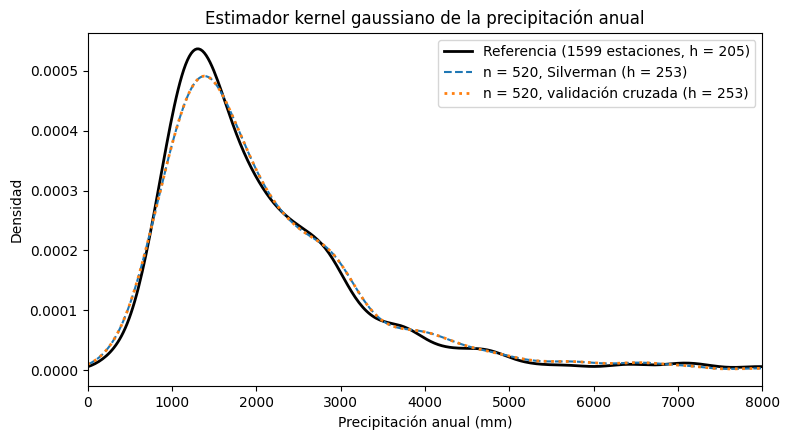

In [ ]:
m = rng.choice(x, size=n_sim, replace=False)
h_s, h_c = h_silverman(m), h_cv(m)
plt.figure(figsize=(8, 4.5))
plt.plot(grid, f_ref, "k-", lw=2, label=f"Referencia ({N} estaciones, h = {h_ref:.0f})")
plt.plot(grid, kde(m, grid, h_s), "--", label=f"n = {n_sim}, Silverman (h = {h_s:.0f})")
plt.plot(grid, kde(m, grid, h_c), ":", lw=2, label=f"n = {n_sim}, validación cruzada (h = {h_c:.0f})")
plt.xlim(0, 8000)
plt.xlabel("Precipitación anual (mm)"); plt.ylabel("Densidad")
plt.title("Estimador kernel gaussiano de la precipitación anual")
plt.legend(); plt.tight_layout(); plt.show()

### Análisis del estimador kernel

**1. Convergencia.** El ancho de banda de Silverman baja al aumentar $n$ (de 362 mm con $n=100$ a 218 mm con $n=1200$) y el error cuadrático integrado cae unas 40 veces, de $9{,}5\times10^{-6}$ a $0{,}23\times10^{-6}$. Con $n=520$ es $1{,}27\times10^{-6}$. La densidad de la muestra se acerca así a la de las 1.599 estaciones, cuyo ancho de banda de Silverman es 205 mm.

**2. Silverman frente a validación cruzada.** En promedio, la validación cruzada elige anchos de banda mayores (por ejemplo, 339 mm frente a 250 mm con $n=520$) y su error es entre 2 y 4 veces el de Silverman. Con una cola derecha tan larga, la validación cruzada de verosimilitud tiende a ensanchar $h$ para dar densidad a las observaciones extremas aisladas. Como la densidad de referencia se calculó con la regla de Silverman, la comparación favorece a esa regla, y esto debe tenerse presente al interpretar la diferencia.

**3. Gráfico.** Con una muestra de 520 estaciones, ambos criterios eligieron el mismo $h$ (253 mm) y las curvas coinciden. Reproducen la forma de la referencia: una moda cerca de 1.300 mm y una cola derecha larga. La densidad de la muestra queda algo más baja en la moda (cerca de 0,00049 frente a 0,00054) y algo más suavizada.

*Conclusión de la sección:* con 500 estaciones o más la densidad estimada es muy próxima a la poblacional y, en estos datos, la regla de Silverman resulta más estable que la validación cruzada.

## 5. Secundaria 1 — Precipitación 1991-2020 frente a 1981-2010 (F2)

Para cada estación con ambos periodos se calcula $d_i=$ precipitación 1991-2020 $-$ precipitación 1981-2010.

**Hipótesis.** $H_0$: la mediana de las diferencias es 0; $H_1$: es distinta de 0. Se usa el estadístico de Wilcoxon de rangos con signo: las diferencias nulas se descartan, los empates entre $|d_i|$ se manejan con rangos medios y la aproximación normal incluye la corrección por empates. El tamaño del efecto es la correlación biserial por rangos, $r=(W^+-W^-)/(W^++W^-)$, y la magnitud del cambio se estima con el estimador de Hodges-Lehmann, la mediana de los promedios de Walsh, con intervalo bootstrap. Como la prueba supone simetría de las diferencias, se revisa el histograma y el sesgo, y se contrasta con la prueba de signos, que no lo requiere.

Pares: 1396 | ceros descartados: 13 | usados: 1383
W+ = 455752.5, W- = 501283.5, z = -1.532, p = 0.1254 (scipy: 0.1254)
Correlación biserial por rangos: -0.048
Hodges-Lehmann: -3.35 mm | IC 95 % bootstrap: [-7.4, 0.7] mm
Mediana de 1991-2020 en los pares: 1701.7 mm -> HL equivale a -0.20 %
Sesgo de las diferencias: -0.69 | prueba de signos: 654 positivas de 1383, p = 0.0466


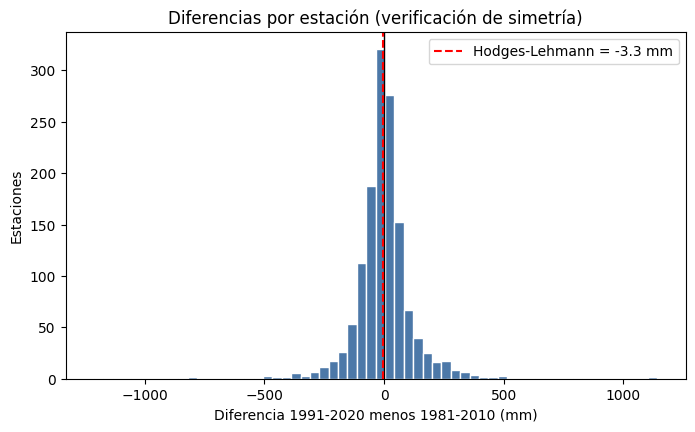

In [ ]:
def wilcoxon_rangos_signo(d):
    d = np.asarray(d, dtype=float)
    d = d[d != 0]                                   # se descartan las diferencias nulas
    n = len(d)
    rangos = stats.rankdata(np.abs(d))              # rangos medios en caso de empate
    w_pos, w_neg = rangos[d > 0].sum(), rangos[d < 0].sum()
    _, cuentas = np.unique(np.abs(d), return_counts=True)
    media = n * (n + 1) / 4
    varianza = n * (n + 1) * (2 * n + 1) / 24 - (cuentas**3 - cuentas).sum() / 48
    z = (w_pos - media) / np.sqrt(varianza)
    return {"n (sin ceros)": n, "W+": w_pos, "W-": w_neg, "z": z,
            "p": 2 * stats.norm.sf(abs(z)), "r biserial": (w_pos - w_neg) / (w_pos + w_neg)}

def hodges_lehmann(d, ti=None, tj=None):
    if ti is None:
        ti, tj = np.triu_indices(len(d))
    return np.median((d[ti] + d[tj]) / 2)

d_nz = dif.to_numpy()[dif.to_numpy() != 0]
res_w = wilcoxon_rangos_signo(dif.to_numpy())
ref_w = stats.wilcoxon(d_nz, zero_method="wilcox", method="approx", correction=False)
assert np.isclose(min(res_w["W+"], res_w["W-"]), ref_w.statistic) and np.isclose(res_w["p"], ref_w.pvalue)

ti, tj = np.triu_indices(len(d_nz))
hl = hodges_lehmann(d_nz, ti, tj)
boot_hl = np.array([hodges_lehmann(rng.choice(d_nz, size=len(d_nz), replace=True), ti, tj) for _ in range(1000)])
ic_hl = np.quantile(boot_hl, [0.025, 0.975])

signos = stats.binomtest(int((d_nz > 0).sum()), len(d_nz), 0.5)

print(f"Pares: {len(dif)} | ceros descartados: {int((dif == 0).sum())} | usados: {len(d_nz)}")
print(f"W+ = {res_w['W+']:.1f}, W- = {res_w['W-']:.1f}, z = {res_w['z']:.3f}, p = {res_w['p']:.4f} (scipy: {ref_w.pvalue:.4f})")
print(f"Correlación biserial por rangos: {res_w['r biserial']:.3f}")
print(f"Hodges-Lehmann: {hl:.2f} mm | IC 95 % bootstrap: [{ic_hl[0]:.1f}, {ic_hl[1]:.1f}] mm")
print(f"Mediana de 1991-2020 en los pares: {pareado['ANUAL_1991_2020'].median():.1f} mm -> HL equivale a {100 * hl / pareado['ANUAL_1991_2020'].median():.2f} %")
print(f"Sesgo de las diferencias: {stats.skew(d_nz):.2f} | prueba de signos: {int((d_nz > 0).sum())} positivas de {len(d_nz)}, p = {signos.pvalue:.4f}")

plt.figure(figsize=(8, 4.5))
plt.hist(d_nz, bins=60, color="#4C78A8", edgecolor="white")
plt.axvline(0, color="black", lw=1); plt.axvline(hl, color="red", ls="--", label=f"Hodges-Lehmann = {hl:.1f} mm")
plt.xlabel("Diferencia 1991-2020 menos 1981-2010 (mm)"); plt.ylabel("Estaciones")
plt.title("Diferencias por estación (verificación de simetría)"); plt.legend(); plt.show()

### Análisis de la pregunta secundaria 1: periodos 1991-2020 y 1981-2010

**1. Prueba de Wilcoxon.** Con 1.383 pares (se descartaron 13 diferencias nulas), $W^+=455.752{,}5$ y $W^-=501.283{,}5$, $z=-1{,}53$ y $p=0{,}125$, igual al de `scipy`. No se rechaza $H_0$ al 5 %: no hay evidencia de una diferencia sistemática entre periodos.

**2. Tamaño del efecto.** La correlación biserial por rangos es $-0{,}048$, un efecto despreciable. El estimador de Hodges-Lehmann es $-3{,}35$ mm, con intervalo bootstrap del 95 % de $[-7{,}4;\;0{,}7]$ mm, que incluye el 0. Equivale a $-0{,}2\,\%$ de la mediana del periodo (1.701,7 mm).

**3. Verificación del supuesto de simetría.** Las diferencias tienen un sesgo de $-0{,}69$, de modo que la simetría se cumple solo de manera aproximada. Por eso se contrasta con la prueba de signos, que no la requiere: 654 de 1.383 diferencias son positivas (47,3 %) y $p=0{,}047$, justo en el límite del 5 %. La evidencia es débil y apunta a una disminución leve en 1991-2020.

**4. Cautelas.** Los dos periodos comparten 20 años (1991-2010) y las estaciones cercanas no son independientes, de modo que los valores $p$ son optimistas. Los resultados no permiten hablar de cambio climático.

*Conclusión de la sección:* no hay una diferencia sistemática relevante entre las normales de ambos periodos; si existe, es de unos pocos milímetros (alrededor de 0,2 %).

## 6. Secundaria 2 — Altitud y precipitación anual (F6)

**Hipótesis.** $H_0$: $\rho_s=0$; $H_1$: $\rho_s\neq 0$. El coeficiente de Spearman es la correlación de Pearson entre los rangos medios (que corrige los empates), con estadístico $t=\rho_s\sqrt{(n-2)/(1-\rho_s^2)}$ y $n-2$ grados de libertad. Como contraste se calcula $\tau_b$ de Kendall, con intervalos bootstrap percentil para ambos coeficientes, y la forma de la relación se describe con una regresión local (loess) de grado 1 con pesos tricúbicos, implementada desde cero.

In [ ]:
def spearman(a, b):
    ra, rb = stats.rankdata(a), stats.rankdata(b)       # rangos medios
    rho = np.corrcoef(ra, rb)[0, 1]
    n = len(a)
    t_est = rho * np.sqrt((n - 2) / (1 - rho**2))
    return rho, 2 * stats.t.sf(abs(t_est), n - 2)

datos_alt = p91v.dropna(subset=["ALTITUD"])
alt, pre = datos_alt["ALTITUD"].to_numpy(), datos_alt["ANUAL"].to_numpy()

rho, p_rho = spearman(alt, pre)
ref_s = stats.spearmanr(alt, pre)
assert np.isclose(rho, ref_s.statistic) and np.isclose(p_rho, ref_s.pvalue)
tau = stats.kendalltau(alt, pre)

B = 1000
rhos, taus = np.empty(B), np.empty(B)
for b in range(B):
    i = rng.integers(0, len(alt), len(alt))
    rhos[b] = spearman(alt[i], pre[i])[0]
    taus[b] = stats.kendalltau(alt[i], pre[i]).statistic
ic_rho, ic_tau = np.percentile(rhos, [2.5, 97.5]), np.percentile(taus, [2.5, 97.5])

print(f"n = {len(alt)} estaciones")
print(f"Spearman rho_s = {rho:.4f}, p = {p_rho:.3g}, IC 95 % bootstrap: [{ic_rho[0]:.4f}, {ic_rho[1]:.4f}]")
print(f"Kendall tau_b = {tau.statistic:.4f}, p = {tau.pvalue:.3g}, IC 95 % bootstrap: [{ic_tau[0]:.4f}, {ic_tau[1]:.4f}]")

n = 1599 estaciones
Spearman rho_s = -0.2264, p = 4.99e-20, IC 95 % bootstrap: [-0.2745, -0.1766]
Kendall tau_b = -0.1557, p = 1.23e-20, IC 95 % bootstrap: [-0.1894, -0.1215]


El máximo de la curva loess está en 130 m, con 2539 mm; en 3824 m la curva da 956 mm

                 estaciones  mediana (mm)
hasta 500 m             723        1918.0
500 a 1.500 m           344        1728.0
1.500 a 2.500 m         343        1839.0
más de 2.500 m          189        1032.0

Estaciones con más de 6.000 mm: 38, todas a menos de 1532 m de altitud


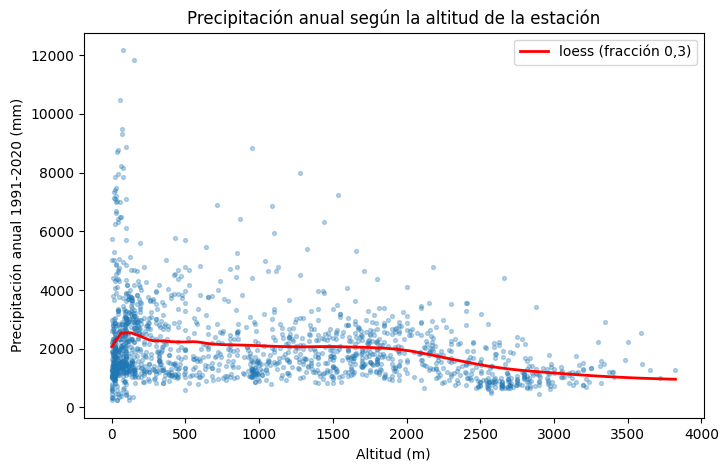

In [ ]:
def loess(xv, yv, malla, frac=0.3):
    """Regresión local lineal con pesos tricúbicos y una fracción frac de vecinos."""
    k = int(np.ceil(frac * len(xv)))
    ajuste = np.empty(len(malla))
    for j, t0 in enumerate(malla):
        d = np.abs(xv - t0)
        idx = np.argpartition(d, k - 1)[:k]
        dmax = d[idx].max()
        w = (1 - (d[idx] / dmax) ** 3) ** 3 if dmax > 0 else np.ones(k)
        X = np.column_stack([np.ones(k), xv[idx] - t0]) * np.sqrt(w)[:, None]
        ajuste[j] = np.linalg.lstsq(X, yv[idx] * np.sqrt(w), rcond=None)[0][0]
    return ajuste

malla_alt = np.linspace(alt.min(), alt.max(), 120)
curva = loess(alt, pre, malla_alt)
pico = malla_alt[np.argmax(curva)]

plt.figure(figsize=(8, 5))
plt.scatter(alt, pre, s=8, alpha=0.3)
plt.plot(malla_alt, curva, color="red", lw=2, label="loess (fracción 0,3)")
plt.xlabel("Altitud (m)"); plt.ylabel("Precipitación anual 1991-2020 (mm)")
plt.title("Precipitación anual según la altitud de la estación"); plt.legend(); plt.show()
print(f"El máximo de la curva loess está en {pico:.0f} m, con {curva.max():.0f} mm; en {malla_alt[-1]:.0f} m la curva da {curva[-1]:.0f} mm")

bandas = pd.cut(alt, [-1, 500, 1500, 2500, np.inf], labels=["hasta 500 m", "500 a 1.500 m", "1.500 a 2.500 m", "más de 2.500 m"])
por_banda = pd.Series(pre).groupby(bandas, observed=True).agg(["size", "median"]).round(0)
por_banda.columns = ["estaciones", "mediana (mm)"]
print()
print(por_banda.to_string())
print(f"\nEstaciones con más de 6.000 mm: {(pre > 6000).sum()}, todas a menos de {alt[pre > 6000].max():.0f} m de altitud")

### Análisis de la pregunta secundaria 2: altitud y precipitación

**1. Asociación.** Spearman da $\rho_s=-0{,}226$ (intervalo bootstrap del 95 % de $[-0{,}275;\,-0{,}177]$) y Kendall $\tau_b=-0{,}156$ ($[-0{,}189;\,-0{,}122]$). Ambos coinciden en el signo y los intervalos excluyen el 0: hay una asociación negativa, pero débil. Que $|\tau|$ sea menor que $|\rho_s|$ es lo habitual entre estos dos coeficientes. El coeficiente propio coincide con el de `scipy`.

**2. Forma de la relación.** El loess muestra que la precipitación sube en los primeros metros (máximo de 2.539 mm hacia 130 m), se mantiene en niveles parecidos hasta cerca de 2.500 m y cae después hasta unos 956 mm a 3.824 m. Por altitud, la mediana es de 1.918 mm hasta 500 m, 1.728 mm entre 500 y 1.500 m, 1.839 mm entre 1.500 y 2.500 m y 1.032 mm por encima de 2.500 m. Las 38 estaciones con más de 6.000 mm están todas por debajo de 1.532 m.

**3. Supuesto de monotonía.** La relación no es monótona en todo el rango: casi no cambia entre 500 y 2.500 m, y la asociación negativa proviene sobre todo de las estaciones de más de 2.500 m. Spearman resume una tendencia general débil, y el loess permite matizarla.

**4. Valores $p$.** Los valores $p$ (del orden de $10^{-20}$) no deben tomarse como evidencia fuerte, pues las estaciones cercanas no son independientes. Son más informativos los coeficientes y sus intervalos.

*Conclusión de la sección:* mayor altitud se asocia con menos precipitación de forma débil, y el efecto se concentra por encima de unos 2.500 m.

## 7. Síntesis y conclusiones

### 7.1 Procedimientos y resultados

| Procedimiento | Familia | Pregunta | Resultado principal | Verificación |
| --- | --- | --- | --- | --- |
| Kolmogorov-Smirnov y simulación de $D_n$ | F3 | Principal | $n\approx 500$ (490 a 520 según la semilla) frente a 738 de DKW | `scipy.stats.ks_2samp` |
| Test de permutación | F1 | Principal | Sin diferencia de medianas ($p$ de 0,18 a 0,92); tasa de rechazo 4,5 % | `scipy.stats.permutation_test` |
| Estimador kernel y selección de $h$ | F5 | Principal | El ISE cae unas 40 veces entre $n=100$ y $n=1200$; Silverman es más estable que la validación cruzada | `scipy.stats.gaussian_kde` |
| Wilcoxon de rangos con signo y Hodges-Lehmann | F2 | Secundaria 1 | $p=0{,}125$; HL de $-3{,}35$ mm; $r=-0{,}048$ | `scipy.stats.wilcoxon` |
| Spearman, Kendall y loess | F6 | Secundaria 2 | $\rho_s=-0{,}226$, $\tau_b=-0{,}156$; relación débil, concentrada sobre 2.500 m | `scipy.stats.spearmanr`, `kendalltau` |

Se cubren cinco familias (F1, F2, F3, F5 y F6) con seis procedimientos, por encima del mínimo de cuatro procedimientos de tres familias.

### 7.2 Respuestas a las preguntas

- **Principal.** Para que la distribución empírica de la precipitación anual quede a menos de 0,05 de la de las 1.599 estaciones, con una confianza del 95 %, bastan alrededor de **500 estaciones** (entre 490 y 520), cerca del 31 % del marco y 32 % menos que las 738 que exige la cota DKW. Con muestreo estratificado por departamento bastan unas **390**. La diferencia con DKW se explica por el muestreo sin reemplazo de una población finita (sección 4.5).
- **Secundaria 1.** No hay evidencia de una diferencia sistemática entre 1991-2020 y 1981-2010 (Wilcoxon $p=0{,}125$). El cambio estimado es de unos $-3$ mm (0,2 %), sin relevancia práctica.
- **Secundaria 2.** Hay una asociación negativa débil entre altitud y precipitación ($\rho_s=-0{,}23$; $\tau_b=-0{,}16$), concentrada en las estaciones de más de 2.500 m.

### 7.3 Limitaciones

- La pregunta principal compara con la distribución de las 1.599 estaciones disponibles, no con la de todo el territorio colombiano.
- Las estaciones cercanas no son independientes, lo que hace optimistas los valores $p$ de las pruebas con más de mil estaciones. Por eso se prioriza el tamaño del efecto y los intervalos bootstrap.
- Los dos periodos comparten 20 años, de modo que la comparación mide sobre todo la diferencia de las décadas no compartidas.
- Los tamaños de muestra por simulación tienen error de Monte Carlo (sección 4.4) y no deben reportarse con una precisión mayor a la decena.
- Los empates (45 valores repetidos y 13 diferencias nulas) se manejaron con rangos medios y descartando los ceros en Wilcoxon; el estadístico de Kolmogorov no se ve afectado por ellos.